In [ ]:
!ls

sample_data


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


OASIS-1 (cross-sectional) shape: (436, 12)
OASIS-2 (longitudinal) shape: (373, 15)

OASIS-1 columns: ['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']
OASIS-2 columns: ['Subject ID', 'MRI ID', 'Group', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']

--- OASIS-2 info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  373 non-null    object 
 1   MRI ID      373 non-null    object 
 2   Group       373 non-null    object 
 3   Visit       373 non-null    int64  
 4   MR Delay    373 non-null    int64  
 5   M/F         373 non-null    object 
 6   Hand        373 non-null    object 
 7   Age         373 non-null    int64  
 8   EDUC        373 non-null    int64  
 9   SES         354 non-null    float64
 10  MMSE        371 non-null    float64
 

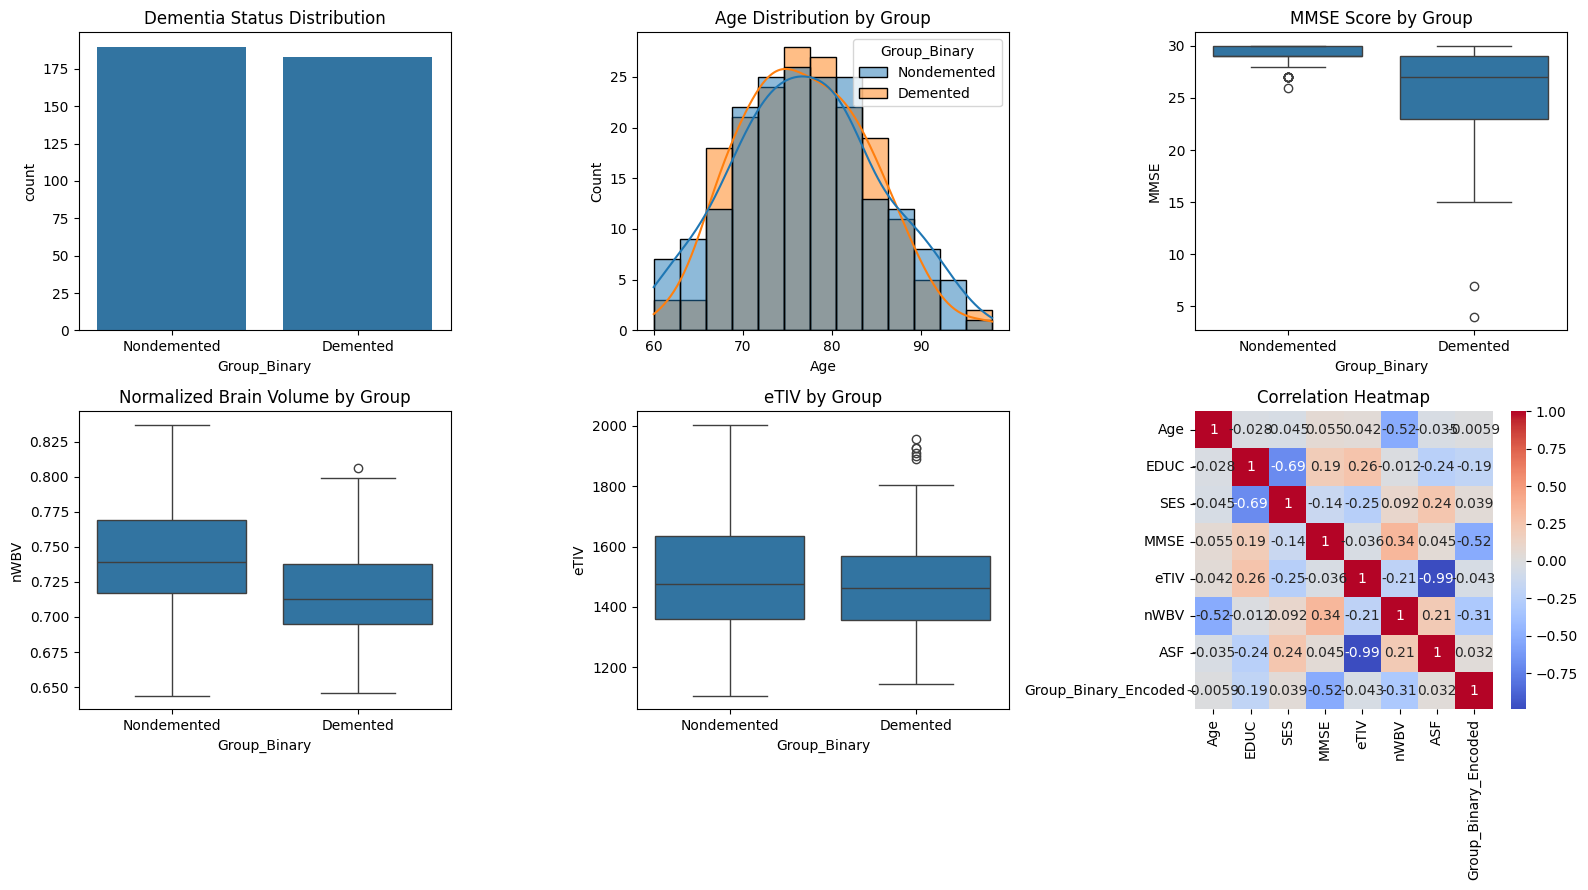


Class balance:
Group_Binary_Encoded
0    0.509383
1    0.490617
Name: proportion, dtype: float64

Saved cleaned dataset: oasis_longitudinal_cleaned.csv

Ready for the next milestone: model building (16 Oct deadline)


In [ ]:
# ============================================================
# OASIS Dementia Prediction — EDA + Preprocessing
# Run this in Google Colab after uploading both CSVs
# ============================================================

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Upload files (run once)
# uploaded = files.upload()   # select oasis_cross-sectional.csv and oasis_longitudinal.csv

# ------------------------------------------------------------
# Step 2: Load both datasets
# ------------------------------------------------------------
df_cross = pd.read_csv("oasis_cross-sectional.csv")   # OASIS-1
df_long  = pd.read_csv("oasis_longitudinal.csv")      # OASIS-2

print("OASIS-1 (cross-sectional) shape:", df_cross.shape)
print("OASIS-2 (longitudinal) shape:", df_long.shape)

print("\nOASIS-1 columns:", df_cross.columns.tolist())
print("OASIS-2 columns:", df_long.columns.tolist())

# ------------------------------------------------------------
# Step 3: Basic inspection
# ------------------------------------------------------------
print("\n--- OASIS-2 info ---")
df_long.info()

print("\n--- OASIS-2 summary stats ---")
print(df_long.describe())

print("\n--- Missing values (OASIS-2) ---")
print(df_long.isnull().sum())

print("\n--- Missing values (OASIS-1) ---")
print(df_cross.isnull().sum())

# ------------------------------------------------------------
# Step 4: Target variable — Group / CDR
# ------------------------------------------------------------
# OASIS-2 has a 'Group' column: Demented, Nondemented, Converted
print("\nGroup value counts (OASIS-2):")
print(df_long['Group'].value_counts())

# We'll simplify 'Converted' into 'Demented' for binary classification,
# since converted patients developed dementia during the study
df_long['Group_Binary'] = df_long['Group'].replace({'Converted': 'Demented'})
print("\nBinary group counts:")
print(df_long['Group_Binary'].value_counts())

# ------------------------------------------------------------
# Step 5: Handle missing values
# ------------------------------------------------------------
# SES and MMSE typically have missing values in OASIS-2
# Justify: fill SES with median (ordinal scale 1-5), MMSE with median too
print("\nMissing before cleaning:")
print(df_long[['SES', 'MMSE']].isnull().sum())

df_long['SES'] = df_long['SES'].fillna(df_long['SES'].median())
df_long['MMSE'] = df_long['MMSE'].fillna(df_long['MMSE'].median())

print("\nMissing after cleaning:")
print(df_long[['SES', 'MMSE']].isnull().sum())

# ------------------------------------------------------------
# Step 6: Encode categorical variables
# ------------------------------------------------------------
df_long['M/F'] = df_long['M/F'].map({'M': 1, 'F': 0})
df_long['Group_Binary_Encoded'] = df_long['Group_Binary'].map({'Nondemented': 0, 'Demented': 1})

# ------------------------------------------------------------
# Step 7: Exploratory visualizations
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(data=df_long, x='Group_Binary', ax=axes[0,0])
axes[0,0].set_title('Dementia Status Distribution')

sns.histplot(data=df_long, x='Age', hue='Group_Binary', kde=True, ax=axes[0,1])
axes[0,1].set_title('Age Distribution by Group')

sns.boxplot(data=df_long, x='Group_Binary', y='MMSE', ax=axes[0,2])
axes[0,2].set_title('MMSE Score by Group')

sns.boxplot(data=df_long, x='Group_Binary', y='nWBV', ax=axes[1,0])
axes[1,0].set_title('Normalized Brain Volume by Group')

sns.boxplot(data=df_long, x='Group_Binary', y='eTIV', ax=axes[1,1])
axes[1,1].set_title('eTIV by Group')

corr_cols = ['Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF', 'Group_Binary_Encoded']
sns.heatmap(df_long[corr_cols].corr(), annot=True, cmap='coolwarm', ax=axes[1,2])
axes[1,2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.savefig("oasis_eda_overview.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# Step 8: Class imbalance check
# ------------------------------------------------------------
print("\nClass balance:")
print(df_long['Group_Binary_Encoded'].value_counts(normalize=True))

# ------------------------------------------------------------
# Step 9: Save cleaned dataset for the next stage (modeling)
# ------------------------------------------------------------
df_long.to_csv("oasis_longitudinal_cleaned.csv", index=False)
print("\nSaved cleaned dataset: oasis_longitudinal_cleaned.csv")
print("\nReady for the next milestone: model building (16 Oct deadline)")


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving oasis_cross-sectional.csv to oasis_cross-sectional.csv
Saving oasis_longitudinal.csv to oasis_longitudinal.csv


In [ ]:
!ls

drive  oasis_cross-sectional.csv  oasis_longitudinal.csv  sample_data


=== Every visit of a patient kept together, 5-fold CV, average of 5 seeds ===
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  AUC lowest seed  AUC highest seed
Logistic Regression     0.777      0.813   0.708     0.757    0.851            0.843             0.858
      Random Forest     0.729      0.739   0.692     0.714    0.786            0.770             0.811
                SVM     0.726      0.740   0.682     0.709    0.781            0.764             0.796


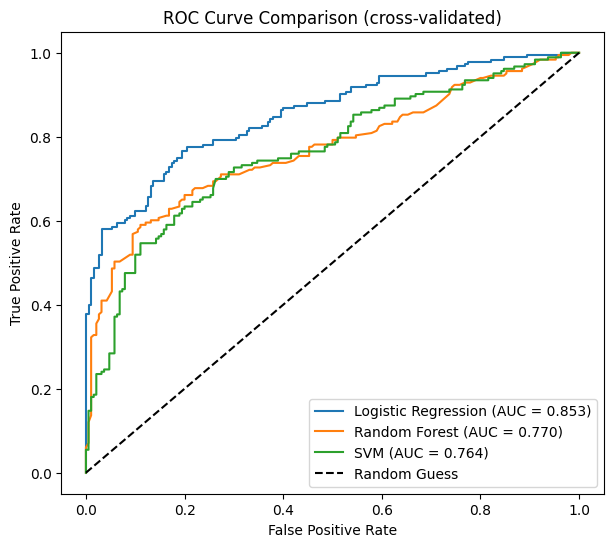

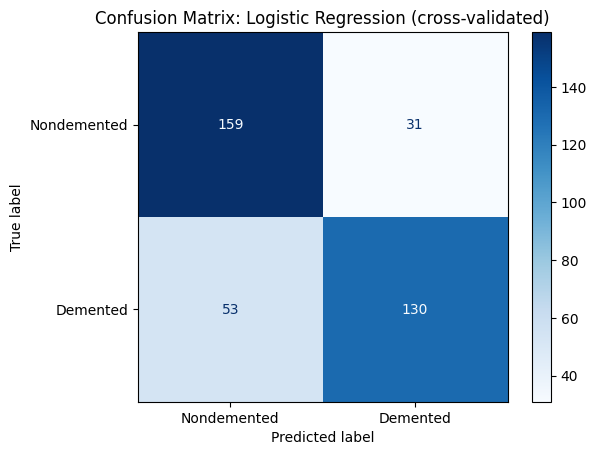

Best model by average ROC-AUC: Logistic Regression


In [ ]:
# OASIS model comparison: Logistic Regression, Random Forest, SVM
# Same 7 features as the final model (no education).
# Visits of one patient always stay together (grouped by Subject ID), and the
# whole thing is repeated with 5 different seeds so one lucky split cannot
# decide the result.
# Needs oasis_longitudinal_cleaned.csv in the Colab file panel.
# Saves: model_comparison_results.csv, roc_curve_comparison.png, confusion_matrix.png

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

df = pd.read_csv("oasis_longitudinal_cleaned.csv")
features = ['eTIV', 'nWBV', 'ASF', 'Age', 'SES', 'MMSE', 'M/F']
X, y, groups = df[features], df['Group_Binary_Encoded'], df['Subject ID']

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
}

all_rows = []
oof_seed0 = {}          # out-of-fold probabilities from seed 0, used for the plots

for seed in range(5):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for name, model in models.items():
        proba = cross_val_predict(model, X, y, cv=cv, groups=groups,
                                  method='predict_proba')[:, 1]
        pred = (proba >= 0.5).astype(int)
        all_rows.append({
            "Model": name, "seed": seed,
            "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred),
            "F1-Score": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba),
        })
        if seed == 0:
            oof_seed0[name] = proba

runs = pd.DataFrame(all_rows)
summary = runs.groupby("Model")[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].mean()
summary["AUC lowest seed"] = runs.groupby("Model")["ROC-AUC"].min()
summary["AUC highest seed"] = runs.groupby("Model")["ROC-AUC"].max()
summary = summary.round(3).reset_index()

print("=== Every visit of a patient kept together, 5-fold CV, average of 5 seeds ===")
print(summary.to_string(index=False))
summary.to_csv("model_comparison_results.csv", index=False)

# ROC curves (seed 0, out-of-fold predictions)
plt.figure(figsize=(7, 6))
for name, proba in oof_seed0.items():
    fpr, tpr, _ = roc_curve(y, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y, proba):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison (cross-validated)")
plt.legend()
plt.savefig("roc_curve_comparison.png", dpi=150)
plt.show()

# Confusion matrix for the model with the best average AUC (seed 0 predictions)
best = summary.loc[summary['ROC-AUC'].idxmax(), 'Model']
cm = confusion_matrix(y, (oof_seed0[best] >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['Nondemented', 'Demented']).plot(cmap='Blues')
plt.title(f"Confusion Matrix: {best} (cross-validated)")
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("Best model by average ROC-AUC:", best)

In [ ]:
!pip install shap

=== 5-fold CV (grouped by patient) ===
  Feature set  Mean ROC-AUC   Std
 Imaging only         0.650 0.047
Clinical only         0.766 0.065
     Combined         0.805 0.042


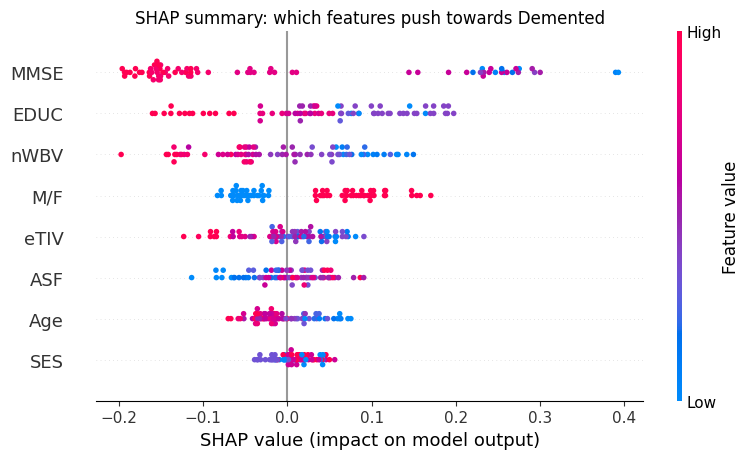


Mean |SHAP| per feature:
MMSE    0.1685
EDUC    0.0873
nWBV    0.0706
M/F     0.0693
eTIV    0.0388
ASF     0.0342
Age     0.0293
SES     0.0186
dtype: float64

Imaging features: 27.8% of total influence
Clinical features: 72.2% of total influence


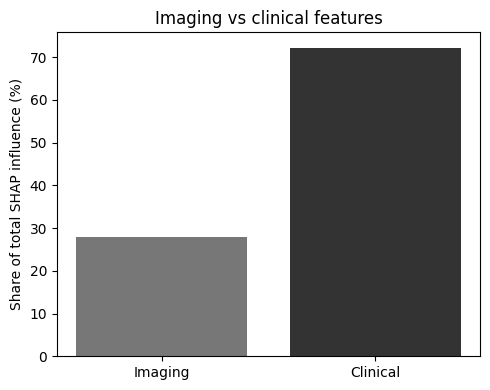

In [ ]:
# OASIS dementia project: modality comparison + SHAP
# Run in the same Colab notebook (needs oasis_longitudinal_cleaned.csv)
# First cell:  !pip install shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score

df = pd.read_csv("oasis_longitudinal_cleaned.csv")

imaging = ['eTIV', 'nWBV', 'ASF']
clinical = ['Age', 'EDUC', 'SES', 'MMSE', 'M/F']
y = df['Group_Binary_Encoded']

# Same patient has several visits in OASIS-2, so split by Subject ID.
# A normal random split can put one person in both train and test
# and make the scores look better than they really are.
groups = df['Subject ID']

# ---------- Part 1: imaging only vs clinical only vs combined ----------
feature_sets = {
    "Imaging only": imaging,
    "Clinical only": clinical,
    "Combined": imaging + clinical,
}

rows = []
for name, feats in feature_sets.items():
    rf = RandomForestClassifier(n_estimators=200, random_state=42)
    scores = cross_val_score(rf, df[feats], y, cv=GroupKFold(n_splits=5),
                             groups=groups, scoring='roc_auc')
    rows.append({"Feature set": name,
                 "Mean ROC-AUC": round(scores.mean(), 3),
                 "Std": round(scores.std(), 3)})

comparison = pd.DataFrame(rows)
print("=== 5-fold CV (grouped by patient) ===")
print(comparison.to_string(index=False))
comparison.to_csv("modality_comparison.csv", index=False)

# ---------- Part 2: SHAP on the combined model ----------
all_feats = imaging + clinical
X = df[all_feats]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(X_test)

# different shap versions return different shapes, pick the "Demented" class
if isinstance(sv, list):
    sv_dem = sv[1]
elif sv.ndim == 3:
    sv_dem = sv[:, :, 1]
else:
    sv_dem = sv

shap.summary_plot(sv_dem, X_test, show=False)
plt.title("SHAP summary: which features push towards Demented")
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150)
plt.show()

# ---------- Part 3: imaging vs clinical share of influence ----------
mean_abs = pd.Series(np.abs(sv_dem).mean(axis=0), index=all_feats)
print("\nMean |SHAP| per feature:")
print(mean_abs.sort_values(ascending=False).round(4))

img_share = mean_abs[imaging].sum() / mean_abs.sum() * 100
clin_share = mean_abs[clinical].sum() / mean_abs.sum() * 100
print(f"\nImaging features: {img_share:.1f}% of total influence")
print(f"Clinical features: {clin_share:.1f}% of total influence")

plt.figure(figsize=(5, 4))
plt.bar(["Imaging", "Clinical"], [img_share, clin_share], color=["#777777", "#333333"])
plt.ylabel("Share of total SHAP influence (%)")
plt.title("Imaging vs clinical features")
plt.tight_layout()
plt.savefig("modality_share.png", dpi=150)
plt.show()


OASIS-1 Educ values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
OASIS-1 SES missing, filled with OASIS-2 median: 18
Rows dropped for other missing values: 0

OASIS-1 test set size: 198
Demented
Demented       100
Nondemented     98
Name: count, dtype: int64

=== Trained on OASIS-2, tested on OASIS-1 ===
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression     0.808      0.816    0.80     0.808    0.896
      Random Forest     0.874      0.850    0.91     0.879    0.938
                SVM     0.813      0.871    0.74     0.800    0.891


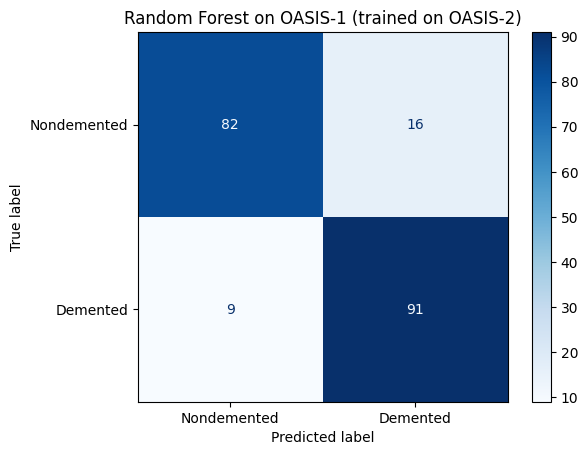

In [ ]:
# OASIS-1 as a second test set
# Train on OASIS-2 (cleaned file), test on OASIS-1 people who have a CDR score.
# Needs in the Colab file panel: oasis_longitudinal_cleaned.csv, oasis_cross-sectional.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

train_df = pd.read_csv("oasis_longitudinal_cleaned.csv")
o1 = pd.read_csv("oasis_cross-sectional.csv")

# In OASIS-1, Educ is a code from 1 to 5. In OASIS-2, EDUC is years of school.
# They are not the same thing, so Education is left out of this test.
print("OASIS-1 Educ values:", sorted(o1['Educ'].dropna().unique()))

# Keep only people who have a CDR score, and ages 60+ (OASIS-2 is 60 to 98)
o1 = o1[o1['CDR'].notna() & (o1['Age'] >= 60)].copy()
o1['M/F'] = o1['M/F'].map({'M': 1, 'F': 0})
# Label rule here: CDR above 0 = demented
o1['Demented'] = (o1['CDR'] > 0).astype(int)

features = ['eTIV', 'nWBV', 'ASF', 'Age', 'SES', 'MMSE', 'M/F']

# Fill missing SES with the OASIS-2 median, same as in training
print("OASIS-1 SES missing, filled with OASIS-2 median:", o1['SES'].isna().sum())
o1['SES'] = o1['SES'].fillna(train_df['SES'].median())

before = len(o1)
o1 = o1.dropna(subset=features)
print("Rows dropped for other missing values:", before - len(o1))

X_train, y_train = train_df[features], train_df['Group_Binary_Encoded']
X_test, y_test = o1[features], o1['Demented']

print("\nOASIS-1 test set size:", len(o1))
print(y_test.value_counts().rename({0: 'Nondemented', 1: 'Demented'}))

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).round(3)
print("\n=== Trained on OASIS-2, tested on OASIS-1 ===")
print(results.to_string(index=False))
results.to_csv("oasis1_test_results.csv", index=False)

rf = models["Random Forest"]
cm = confusion_matrix(y_test, rf.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=['Nondemented', 'Demented']).plot(cmap='Blues')
plt.title("Random Forest on OASIS-1 (trained on OASIS-2)")
plt.savefig("oasis1_confusion_matrix.png", dpi=150)
plt.show()


=== 5-fold CV grouped by patient, repeated with 5 seeds ===
  Feature set  Mean ROC-AUC  Lowest seed  Highest seed
 Imaging only         0.639        0.619         0.655
Clinical only         0.742        0.739         0.744
     Combined         0.793        0.777         0.817


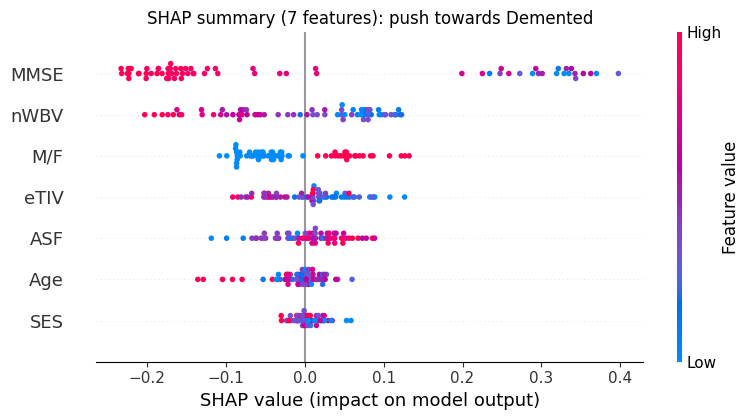


=== Imaging vs clinical share of SHAP influence, 5 splits ===
 seed  Imaging %  Clinical % Top feature
    0       34.3        65.7        MMSE
    1       30.9        69.1        MMSE
    2       36.1        63.9        MMSE
    3       33.3        66.7        MMSE
    4       36.9        63.1        MMSE

Imaging % average: 34.3 | range: 30.9 to 36.9


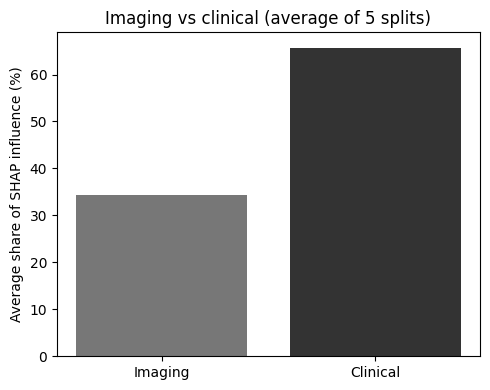


Saved model.pkl and requirements.txt
Download both from the file panel for the dashboard step.


In [ ]:
# OASIS final model (7 features, no education)
# Run in Colab after:  !pip install shap
# Needs oasis_longitudinal_cleaned.csv in the file panel.
# Saves: model.pkl, final_model_summary.csv, shap_summary_final.png, modality_share_final.png

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, cross_val_score

df = pd.read_csv("oasis_longitudinal_cleaned.csv")

imaging = ['eTIV', 'nWBV', 'ASF']
clinical = ['Age', 'SES', 'MMSE', 'M/F']
all_feats = imaging + clinical
y = df['Group_Binary_Encoded']
groups = df['Subject ID']          # keep one patient's visits together

# ---------- 1. Imaging vs clinical vs combined, repeated with 5 seeds ----------
sets = {"Imaging only": imaging, "Clinical only": clinical, "Combined": all_feats}
rows = []
for name, feats in sets.items():
    seed_means = []
    for seed in range(5):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        rf = RandomForestClassifier(n_estimators=200, random_state=seed)
        s = cross_val_score(rf, df[feats], y, cv=cv, groups=groups, scoring='roc_auc')
        seed_means.append(s.mean())
    rows.append({"Feature set": name,
                 "Mean ROC-AUC": round(np.mean(seed_means), 3),
                 "Lowest seed": round(min(seed_means), 3),
                 "Highest seed": round(max(seed_means), 3)})

summary = pd.DataFrame(rows)
print("=== 5-fold CV grouped by patient, repeated with 5 seeds ===")
print(summary.to_string(index=False))
summary.to_csv("final_model_summary.csv", index=False)

# ---------- 2. SHAP on 5 different patient splits ----------
def dementia_shap(sv):
    if isinstance(sv, list):
        return sv[1]
    if sv.ndim == 3:
        return sv[:, :, 1]
    return sv

X = df[all_feats]
shares = []
for seed in range(5):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(X, y, groups))
    rf = RandomForestClassifier(n_estimators=200, random_state=seed).fit(X.iloc[tr], y.iloc[tr])
    sv = dementia_shap(shap.TreeExplainer(rf).shap_values(X.iloc[te]))
    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=all_feats)
    shares.append({"seed": seed,
                   "Imaging %": round(mean_abs[imaging].sum() / mean_abs.sum() * 100, 1),
                   "Clinical %": round(mean_abs[clinical].sum() / mean_abs.sum() * 100, 1),
                   "Top feature": mean_abs.idxmax()})
    if seed == 0:
        shap.summary_plot(sv, X.iloc[te], show=False)
        plt.title("SHAP summary (7 features): push towards Demented")
        plt.tight_layout()
        plt.savefig("shap_summary_final.png", dpi=150)
        plt.show()

shares_df = pd.DataFrame(shares)
print("\n=== Imaging vs clinical share of SHAP influence, 5 splits ===")
print(shares_df.to_string(index=False))
print("\nImaging % average:", round(shares_df['Imaging %'].mean(), 1),
      "| range:", shares_df['Imaging %'].min(), "to", shares_df['Imaging %'].max())

avg = [shares_df['Imaging %'].mean(), shares_df['Clinical %'].mean()]
plt.figure(figsize=(5, 4))
plt.bar(["Imaging", "Clinical"], avg, color=["#777777", "#333333"])
plt.ylabel("Average share of SHAP influence (%)")
plt.title("Imaging vs clinical (average of 5 splits)")
plt.tight_layout()
plt.savefig("modality_share_final.png", dpi=150)
plt.show()

# ---------- 3. Final model for the dashboard (trained on all OASIS-2 rows) ----------
final_rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)
joblib.dump({
    "model": final_rf,
    "features": all_feats,
    "imaging": imaging,
    "clinical": clinical,
    # ASF is worked out from eTIV (ASF x eTIV is almost constant), so the
    # dashboard only asks for eTIV and calculates ASF itself
    "asf_const": float((df['ASF'] * df['eTIV']).median()),
    "ranges": {c: [float(df[c].min()), float(df[c].max())]
               for c in ['Age', 'MMSE', 'eTIV', 'nWBV']},
}, "model.pkl")

# requirements.txt for deployment: scikit-learn must match the version that
# built model.pkl, otherwise the saved model may not load on the server
import sklearn
with open("requirements.txt", "w") as f:
    f.write("streamlit\npandas\nnumpy\nmatplotlib\nshap\njoblib\n"
            f"scikit-learn=={sklearn.__version__}\n")

print("\nSaved model.pkl and requirements.txt")
print("Download both from the file panel for the dashboard step.")